# Phase 2: Pipeline Execution and Visual Diagnostics

**A Monthly Early Warning System for Food Price Spikes in Nigerian States**
04-652 Artificial Intelligence System Design, Fall 2026
Nimat Ohunene Sadiq, Carnegie Mellon University Africa

This notebook executes the Phase 1 strategy. It builds the modelling panel from
the raw WFP file, generates the eight required diagnostic figures, fits both
model pipelines with transformations isolated to the training split, and
verifies that no leakage is present.

Deviations from the Phase 1 plan are flagged inline as **DEVIATION** and
collected in the decision log of `Phase2_Final_Report.pdf`.

## 0. Environment and data

In [1]:
# On Colab, uncomment the next two lines:
# !git clone https://github.com/nimatsadiq/AISD_proj_F26.git
# %cd AISD_proj_F26
# !pip install -q -r requirements.txt

import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
import numpy as np
import pandas as pd

# Resolve the repository root so relative paths work whether this notebook is
# run from the repo root, from notebooks/, or from Colab.
ROOT = pathlib.Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
import os; os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Repository root:", ROOT)
pd.set_option("display.width", 120)

Repository root: /home/claude/repo


In [2]:
# The raw file is NOT in version control (see .gitignore). It is fetched here so
# the notebook reproduces from a clean clone. HDX revises this dataset in place,
# so the row count and file date are printed and should be recorded alongside
# any results.
import json, urllib.request

RAW_PATH = pathlib.Path("data/raw/wfp_food_prices_nga.csv")
HDX_API = "https://data.humdata.org/api/3/action/package_show?id=wfp-food-prices-for-nigeria"

if not RAW_PATH.exists():
    RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(HDX_API, timeout=60) as r:
        resources = json.load(r)["result"]["resources"]
    url = next(x["url"] for x in resources if x["name"].lower().endswith("food prices"))
    print("Downloading from HDX ...")
    urllib.request.urlretrieve(url, RAW_PATH)
    print("Saved to", RAW_PATH)
else:
    print("Using the existing local copy at", RAW_PATH)

raw = pd.read_csv(RAW_PATH)
print("Raw matrix (N x P):", raw.shape)
print("Date range:", raw.date.min(), "to", raw.date.max())
print("Missing cells:", int(raw.isna().sum().sum()))
print("File date:", pd.Timestamp(RAW_PATH.stat().st_mtime, unit="s").date())
raw.head(3)

Using the existing local copy at data/raw/wfp_food_prices_nga.csv


Raw matrix (N x P): (88545, 16)
Date range: 2002-01-15 to 2026-07-15
Missing cells: 0
File date: 2026-10-20


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Maize,51,KG,actual,Wholesale,NGN,175.92,1.54
1,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Millet,73,KG,actual,Wholesale,NGN,150.18,1.31
2,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Rice (imported),64,KG,actual,Wholesale,NGN,358.70,3.14


### 0.1 Audit note: the raw file has no missing values

All rows are complete, because WFP publishes only observed records. A market
that fails to report produces **no row at all**. Missingness is structural and
becomes visible only after reshaping onto a continuous monthly grid, which is
what `PanelBuilder` does next.

## 1. Build the modelling panel

In [3]:
from src.pipeline_builder import (
    build_panel, temporal_split, TARGET,
    NUMERIC_FEATURES, RATIO_FEATURES, CATEGORICAL_FEATURES,
    MISSINGNESS_FEATURES, DROPPED_ZERO_VARIANCE,
    build_logistic_pipeline, build_tree_pipeline,
    seasonal_persistence_baseline, set_positive_class_weight,
)
from src.transformers import RatioCapper

panel = build_panel(raw, threshold=0.15)

print("Panel matrix (N x P):", panel.shape)
print("Series (state x commodity):", panel.groupby(['state','commodity']).ngroups)
print("Cells observed: {:.1%}".format(1 - panel.is_gap.mean()))
print("Gap months:", int(panel.is_gap.sum()))
print("Single-month gaps interpolated:", int(panel.price_was_interpolated.sum()))
print()
print("Labelled rows:", int(panel[TARGET].notna().sum()))
print("Positives: {} ({:.1%})".format(int(panel[TARGET].sum()), panel[TARGET].mean()))

Panel matrix (N x P): (9000, 32)
Series (state x commodity): 107
Cells observed: 87.4%
Gap months: 1132
Single-month gaps interpolated: 356

Labelled rows: 6940
Positives: 1300 (18.7%)


### 1.1 Temporal split

Forward chronological, approximately 70/15/15 by time. Random splitting is
inadmissible: price series are autocorrelated, so a randomly held-out month
sits between two training months that nearly determine it.

Stratification is deliberately not applied, because it requires reshuffling,
which would destroy the ordering this design exists to respect. The class
balance of each split is reported instead.

In [4]:
train, val, test = temporal_split(panel, train_end="2023-06-30", val_end="2024-12-31")
splits = {"Train": train, "Validation": val, "Test": test}

for name, d in splits.items():
    print("{:11} n={:5}  positives={:4} ({:5.1%})  {} to {}".format(
        name, len(d), int(d[TARGET].sum()), d[TARGET].mean(),
        d.month.min().date(), d.month.max().date()))

Train       n= 4956  positives= 810 (16.3%)  2016-03-01 to 2023-06-01
Validation  n= 1075  positives= 375 (34.9%)  2023-07-01 to 2024-12-01
Test        n=  909  positives= 115 (12.7%)  2025-01-01 to 2026-06-01


**DEVIATION 1 (observed, not planned).** The validation window carries a far
higher positive rate than train or test. It spans the post-float,
high-inflation period of 2023 to 2024, so the structural break the Phase 1
report anticipated is visible directly in the class balance. Model selection
therefore happens under harsher conditions than the test period, which makes
the test estimate conservative rather than optimistic.

**DEVIATION 2.** Phase 1 planned four missingness features. `is_gap` and
`months_since_obs` are constant inside the modelling set: a gap month has no
price, therefore no trailing mean, therefore no label, so it is never a
modelled row. Both are dropped. The MNAR signal survives through
`gaps_last_6m` and `price_was_interpolated`, which describe gaps in a row's
recent history rather than in the row itself.

In [5]:
print("Dropped (zero variance after labelling):", DROPPED_ZERO_VARIANCE)
print("Retained missingness features:", MISSINGNESS_FEATURES)
train[DROPPED_ZERO_VARIANCE + MISSINGNESS_FEATURES].nunique().to_frame("distinct values")

Dropped (zero variance after labelling): ['is_gap', 'months_since_obs']
Retained missingness features: ['gaps_last_6m', 'price_was_interpolated']


,distinct values
is_gap,1
months_since_obs,1
gaps_last_6m,4
price_was_interpolated,2


## 2. The eight diagnostic figures

In [6]:
from src import figures as F

FIGDIR = "figures"
capper = RatioCapper(columns=RATIO_FEATURES).fit(train[RATIO_FEATURES])  # train-fitted

paths = []
paths.append(F.fig1_1_missingness_heatmap(panel, FIGDIR))
paths.append(F.fig1_2_target_distribution(panel, splits, FIGDIR))
paths.append(F.fig2_1_outlier_boxplots(train, capper, FIGDIR))
p31, flagged = F.fig3_1_correlation_heatmap(train, FIGDIR, thresh=0.85)
paths.append(p31)
paths.append(F.fig3_2_collinear_scatter(train, flagged, FIGDIR))
paths.append(F.fig3_3_feature_importance(train, FIGDIR))
paths.append(F.fig4_1_transformation_grid(train, "price", FIGDIR))
paths.append(F.fig5_1_pca_scree(train, FIGDIR))

for p in paths:
    print("wrote", p)
print()
print("Collinear pairs at |rho| >= 0.85:", flagged)

wrote figures/fig1_1_missingness_heatmap.png
wrote figures/fig1_2_target_distribution.png
wrote figures/fig2_1_outlier_boxplots.png
wrote figures/fig3_1_correlation_matrix.png
wrote figures/fig3_2_collinear_scatterplots.png
wrote figures/fig3_3_target_importance.png
wrote figures/fig4_1_transformation_grid.png
wrote figures/fig5_1_pca_scree_plot.png

Collinear pairs at |rho| >= 0.85: [('mom_3m', 'dev_from_6m', np.float64(0.8760226294735236))]


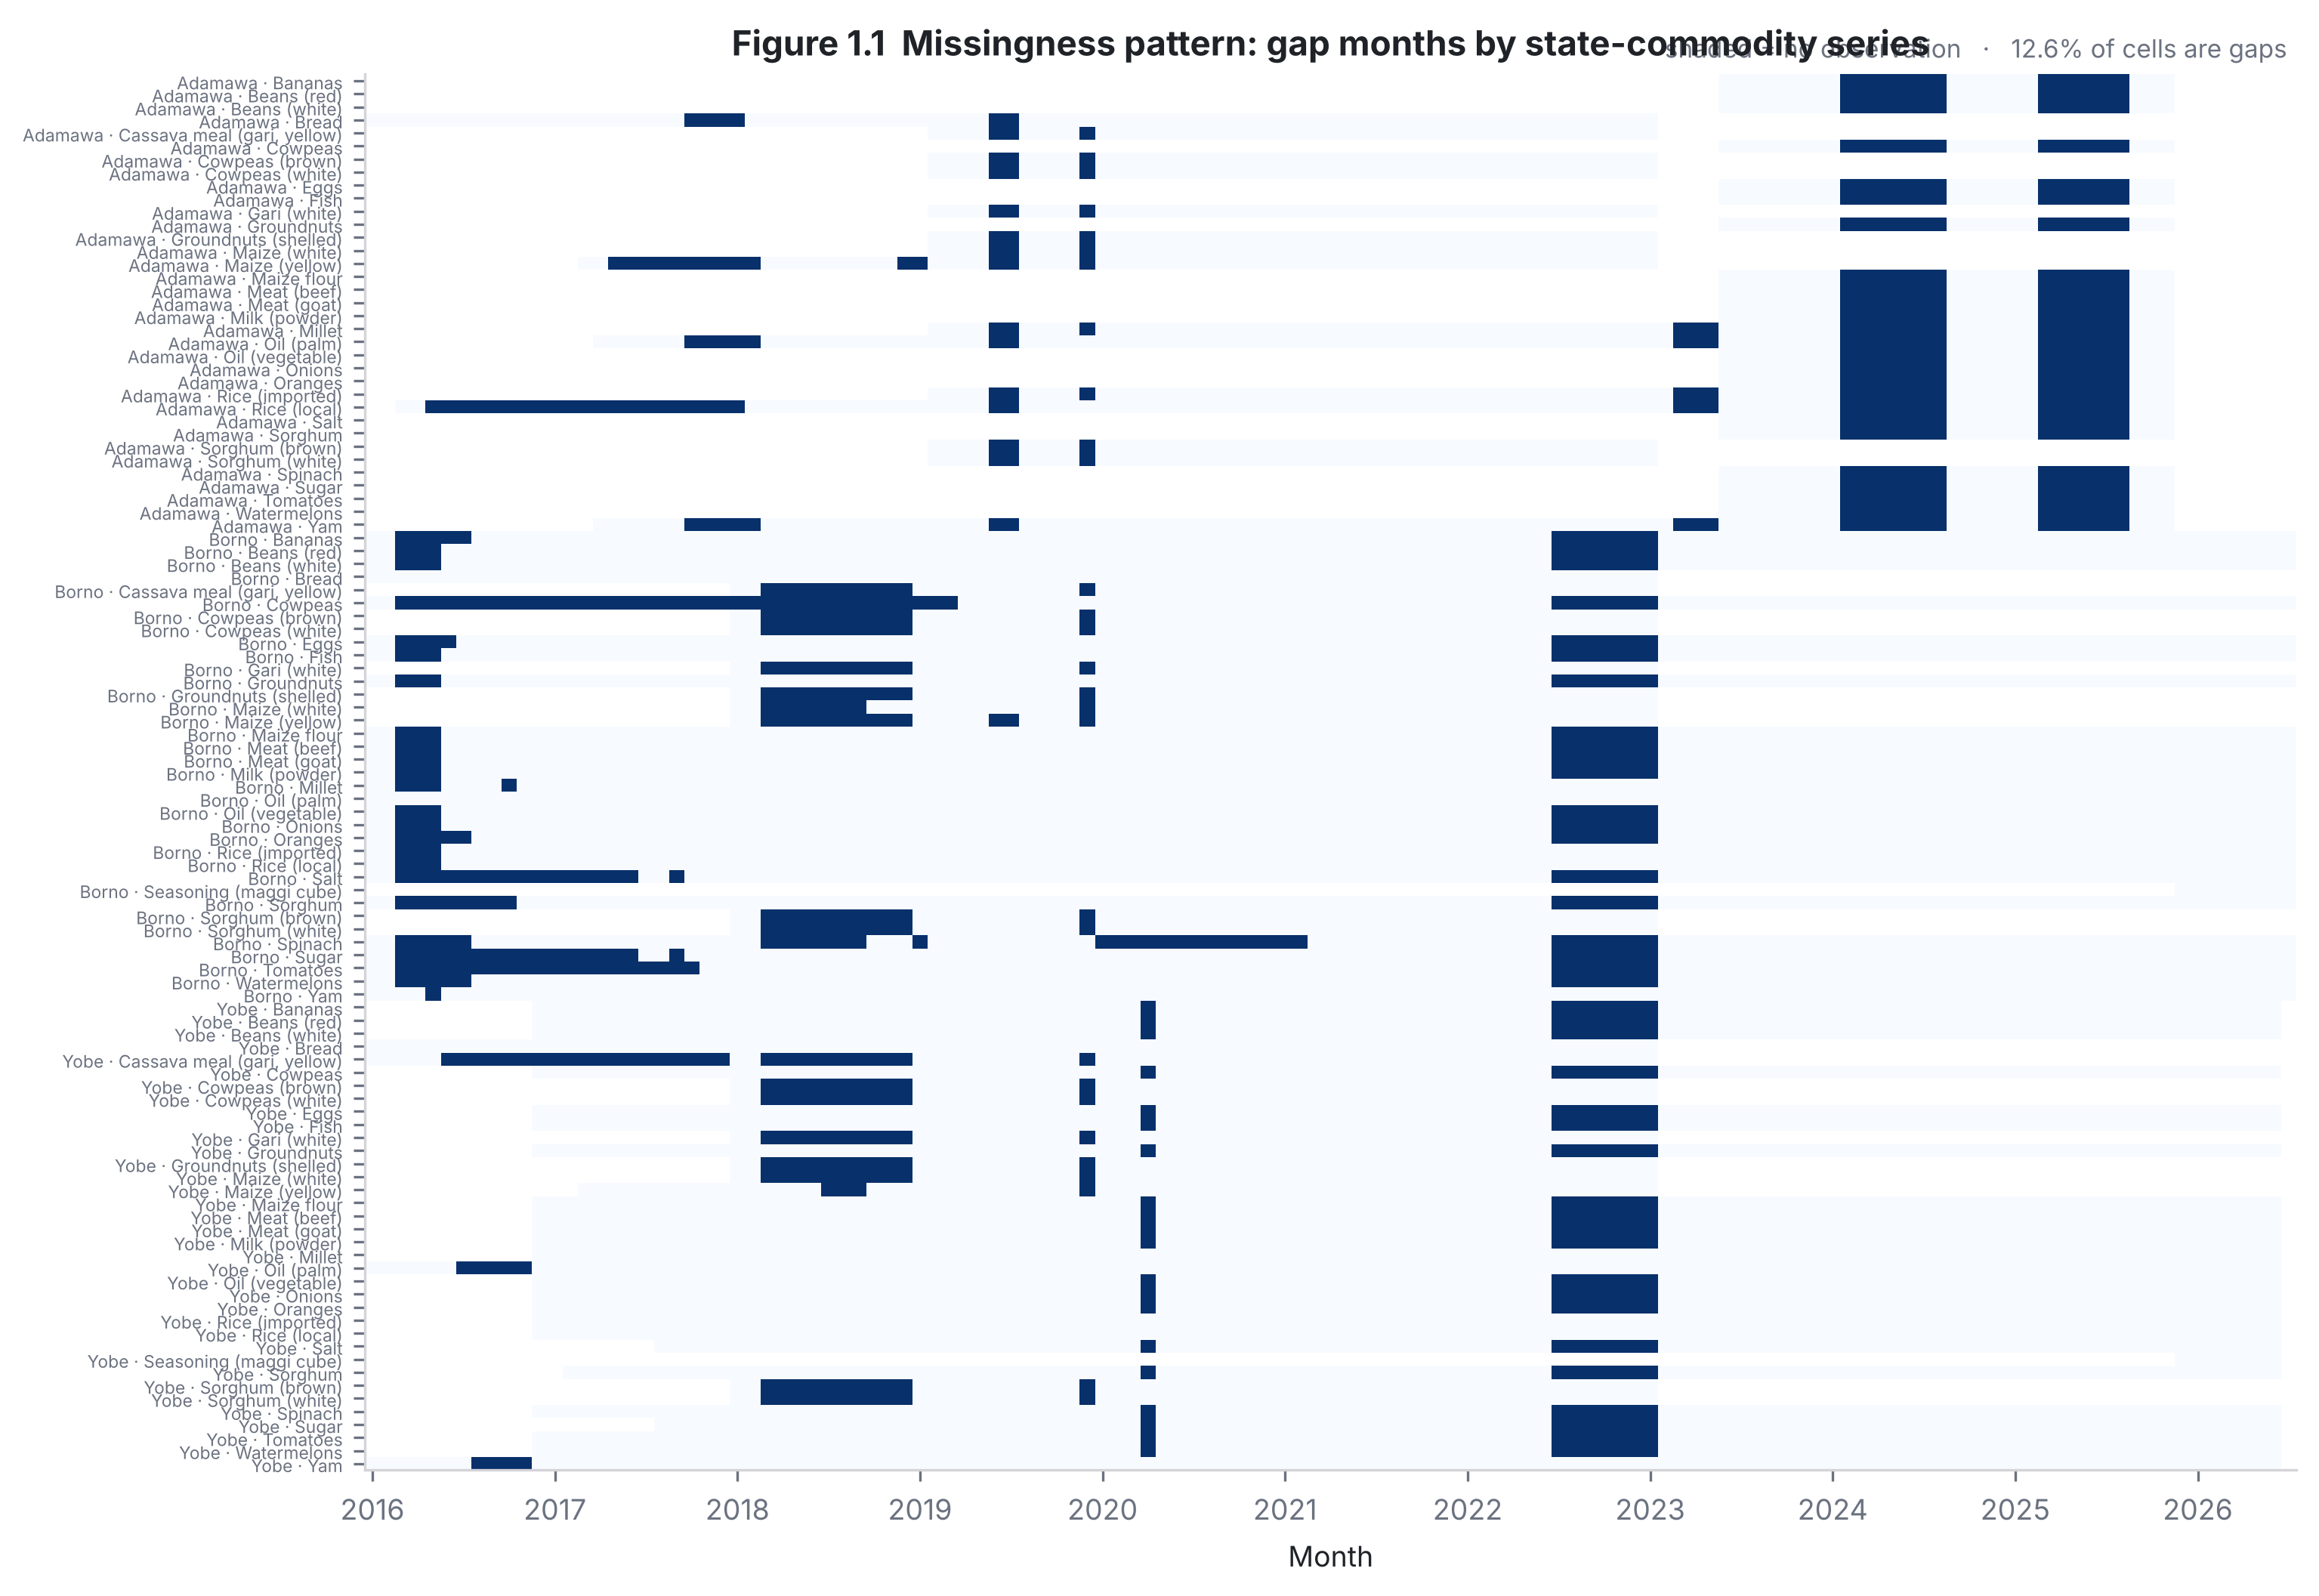

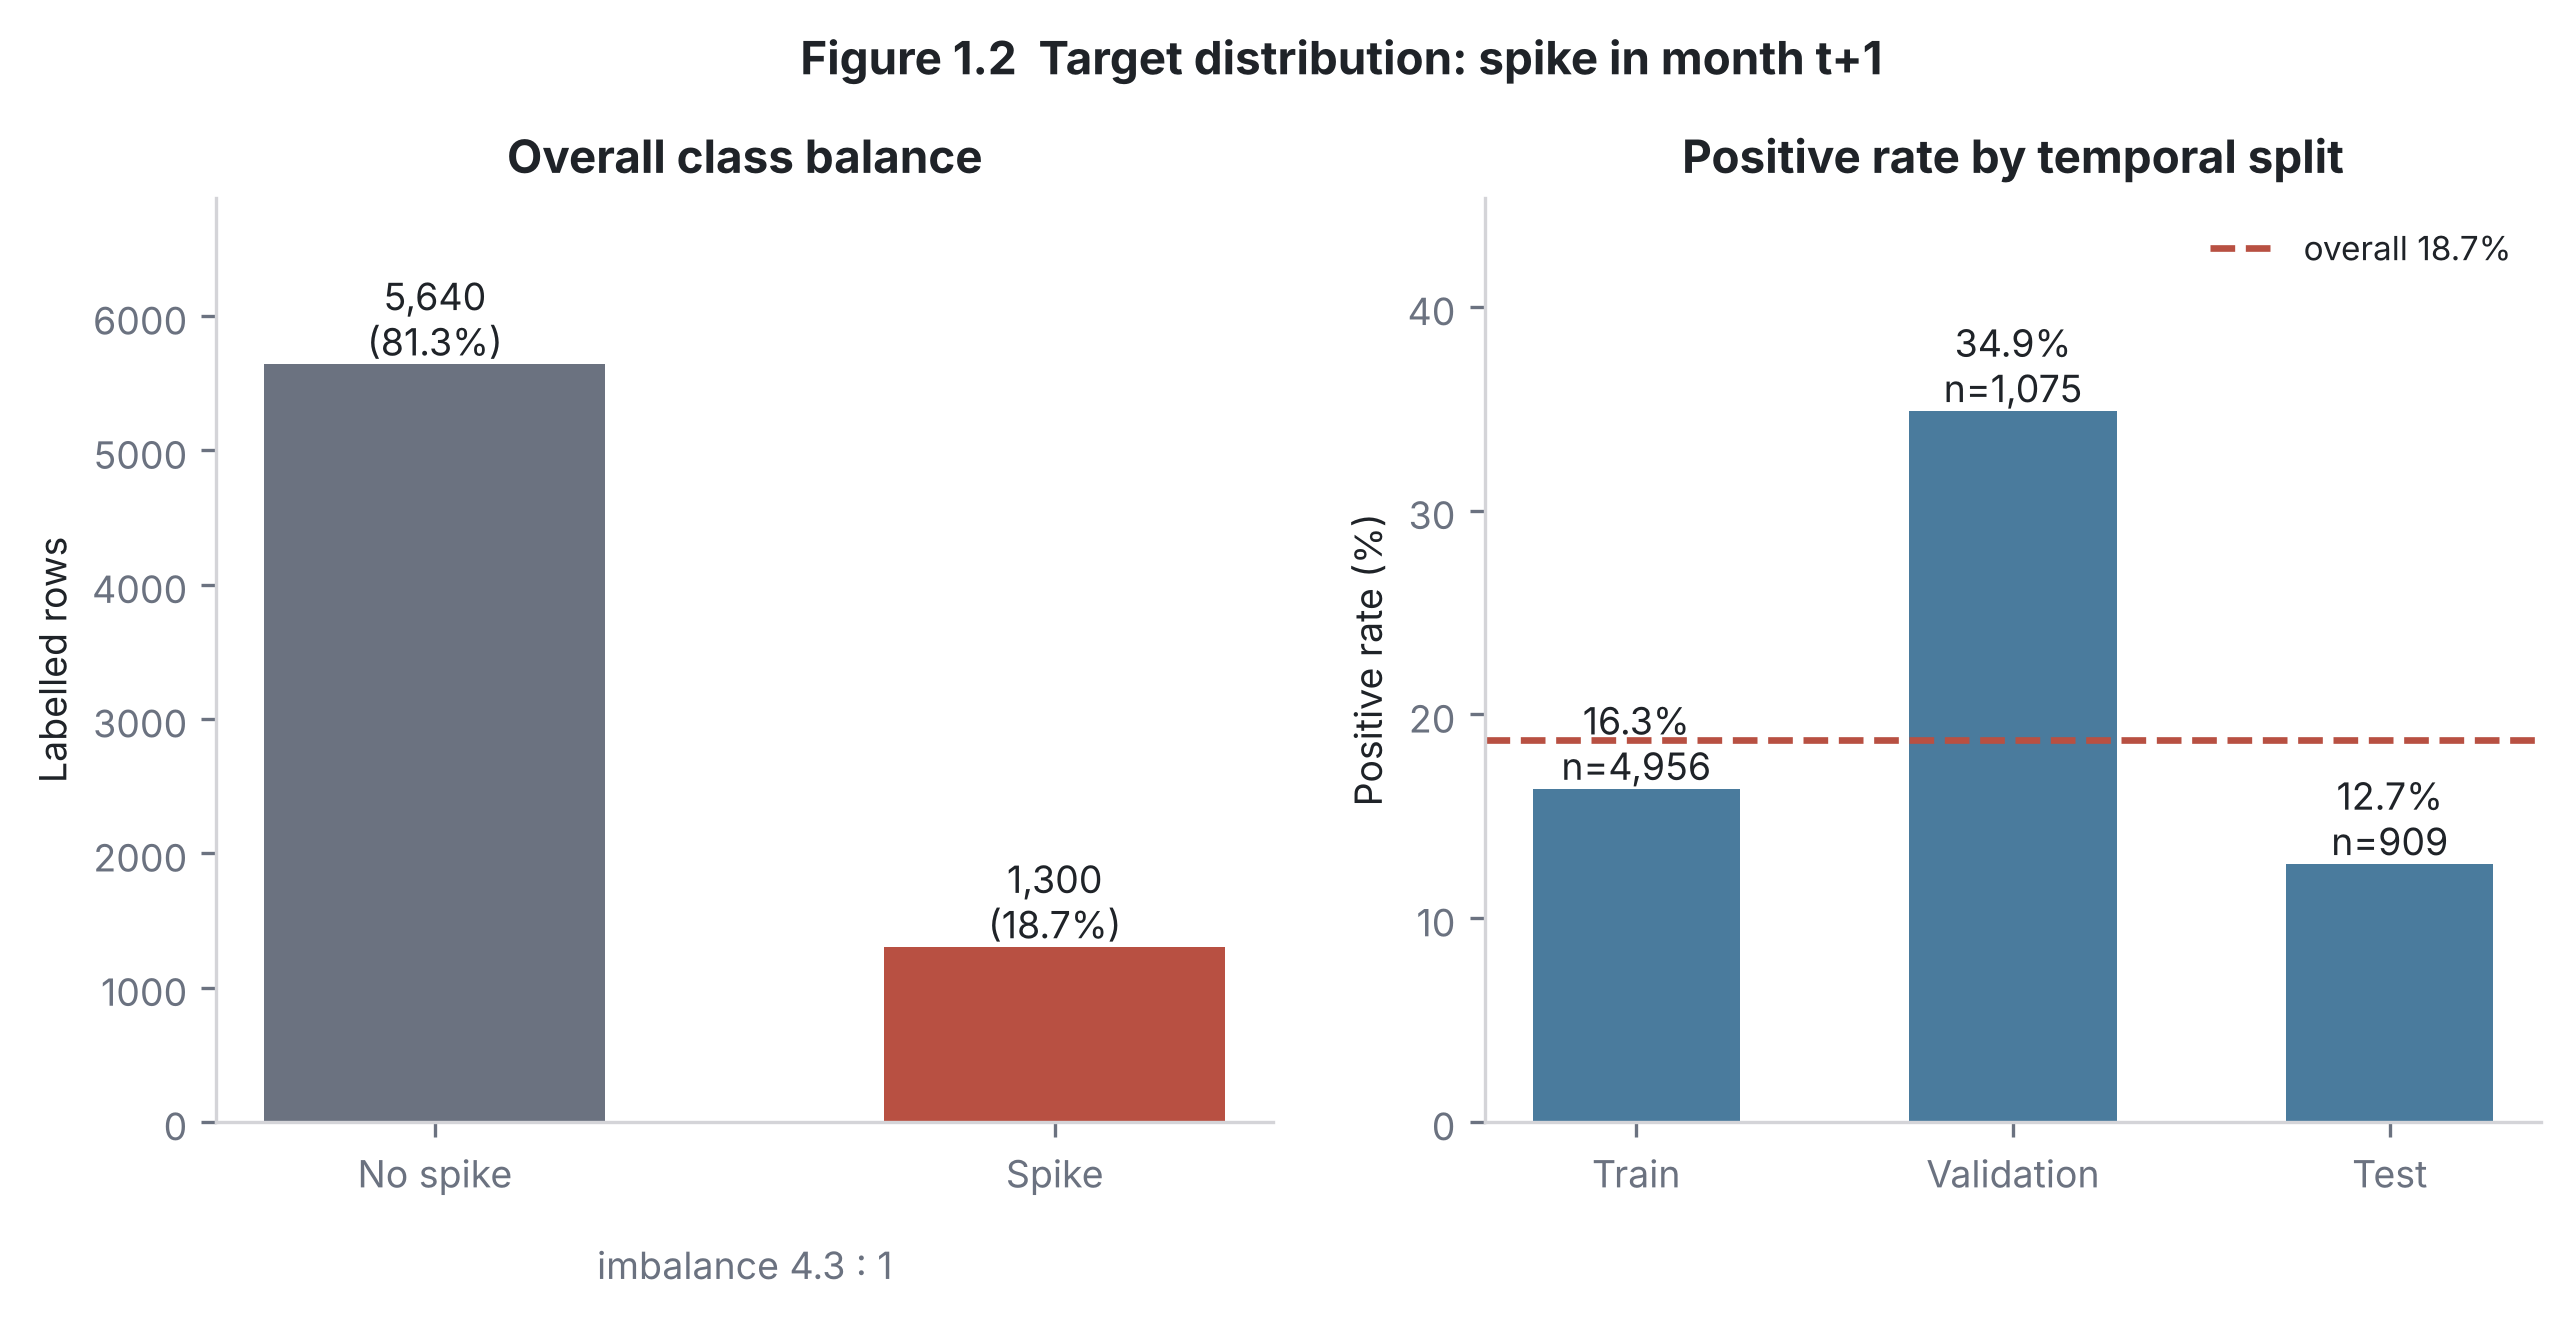

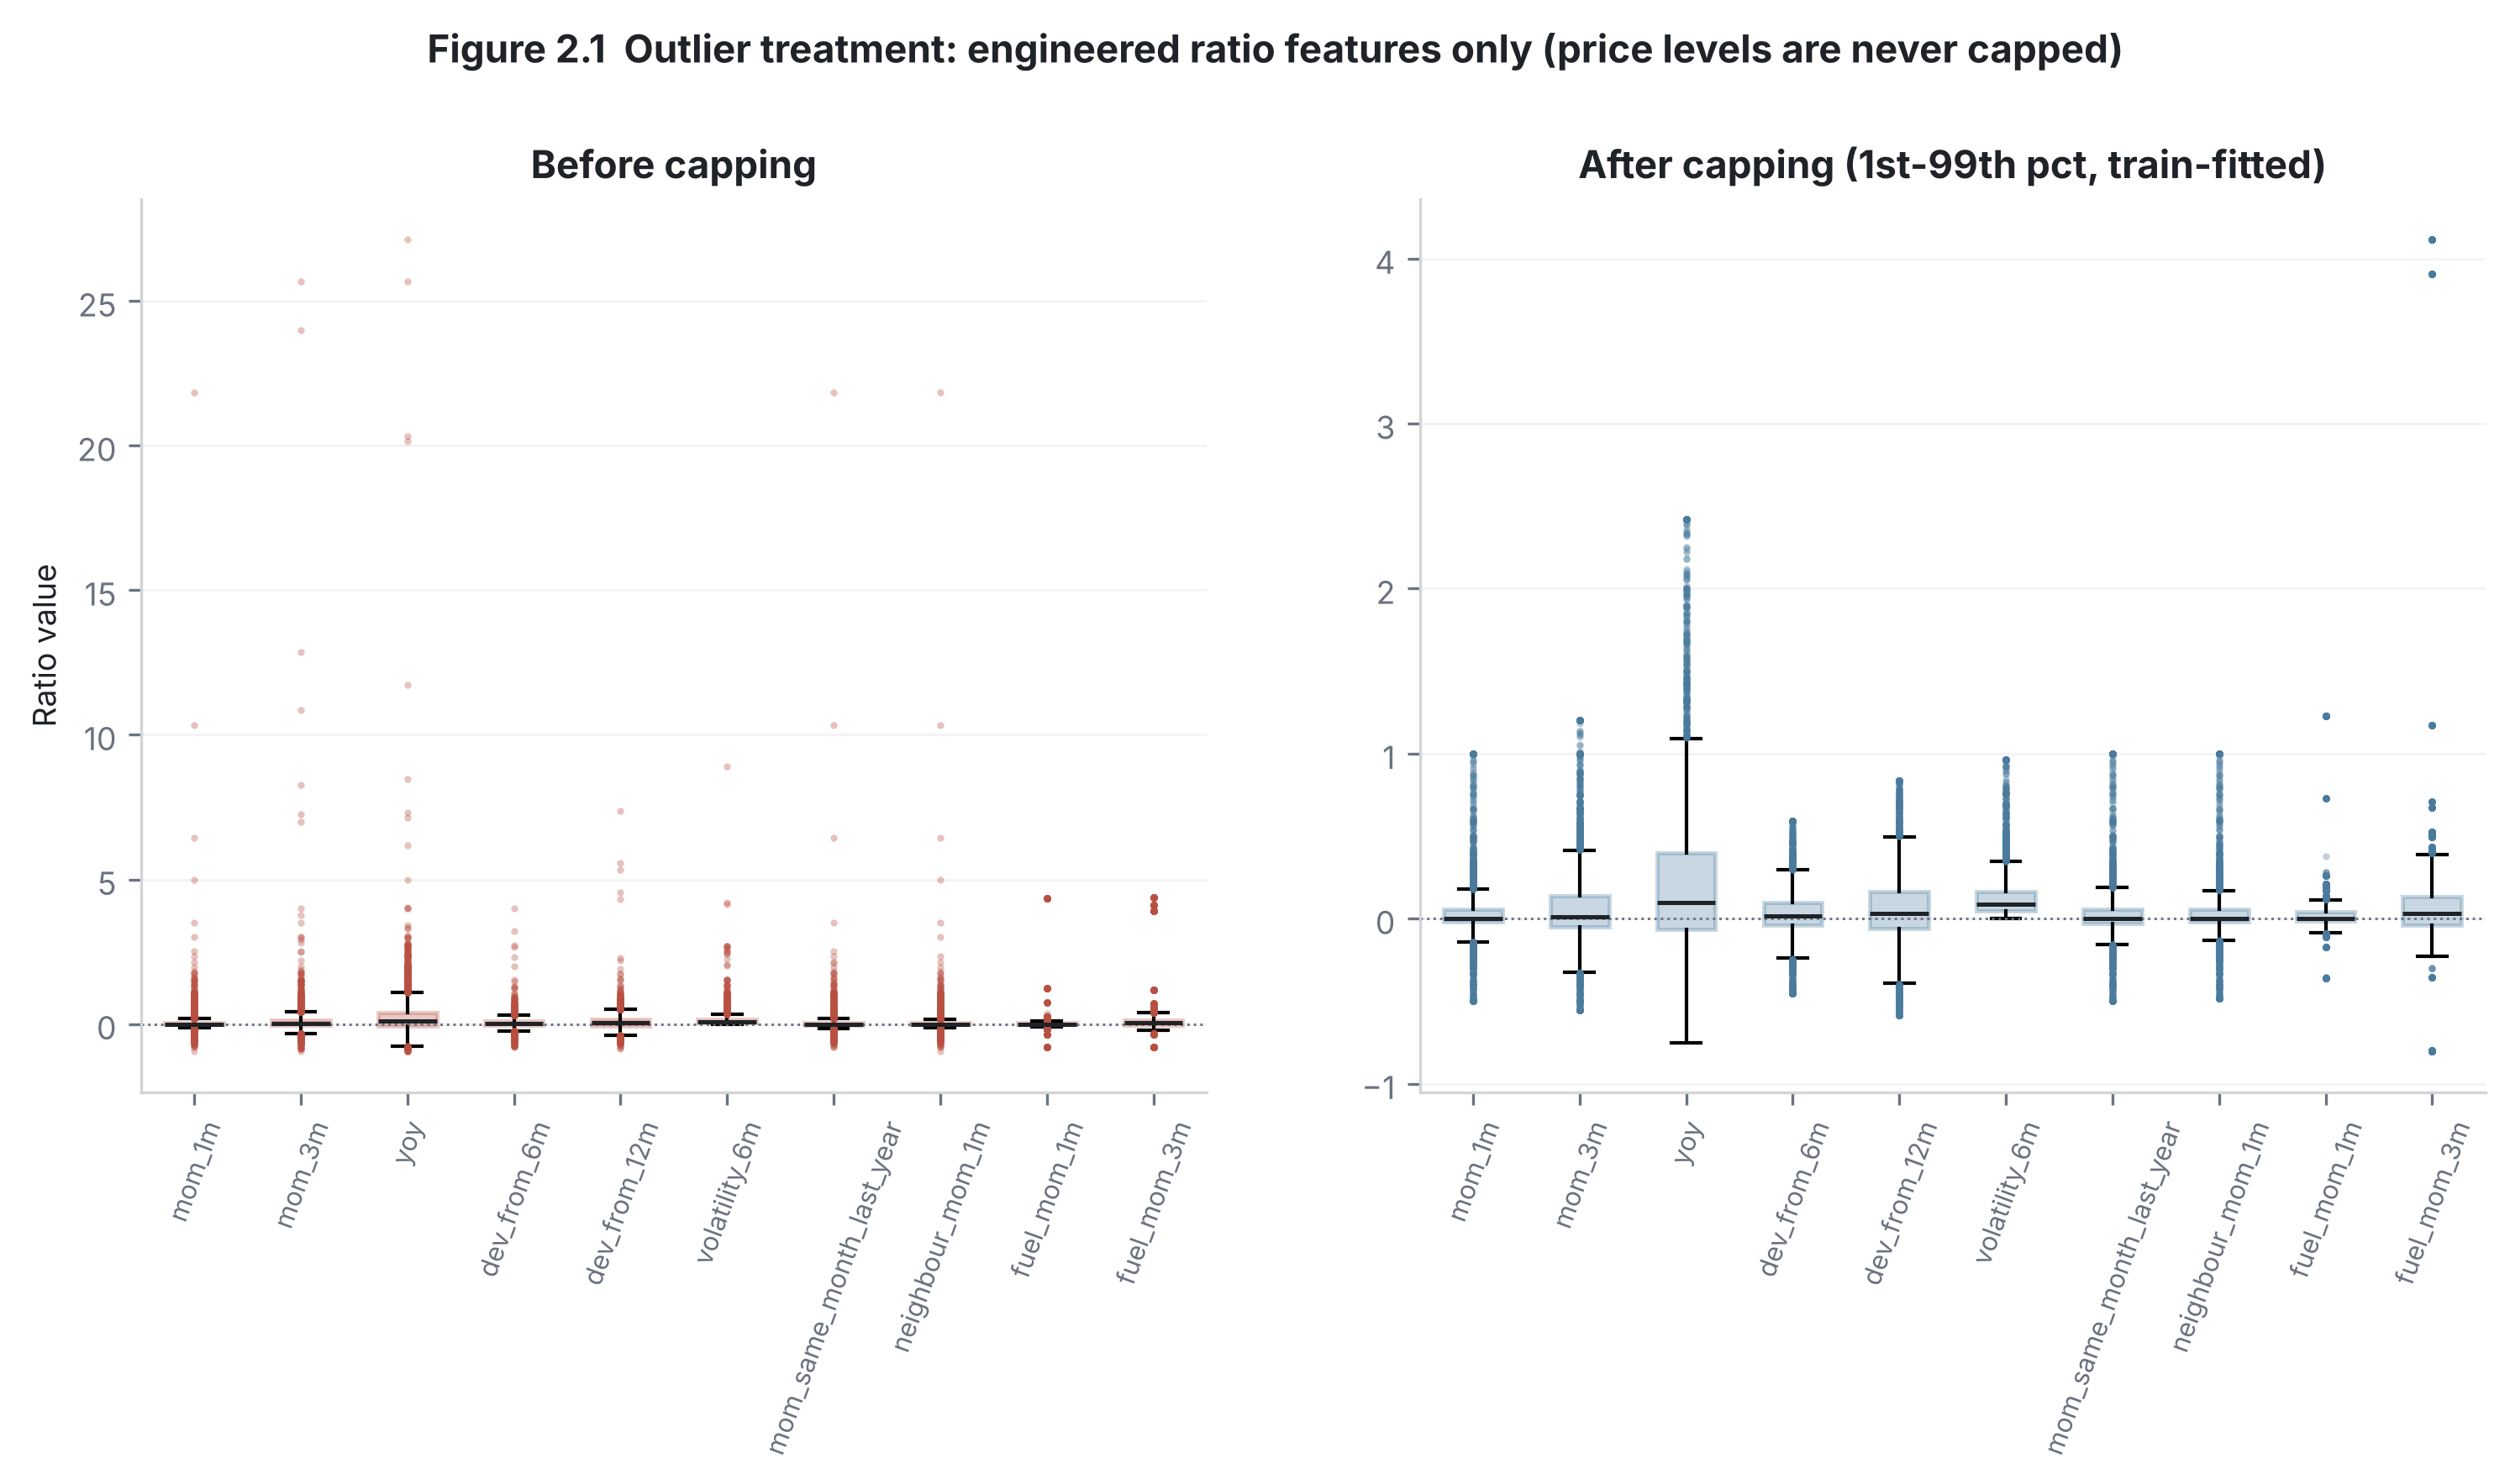

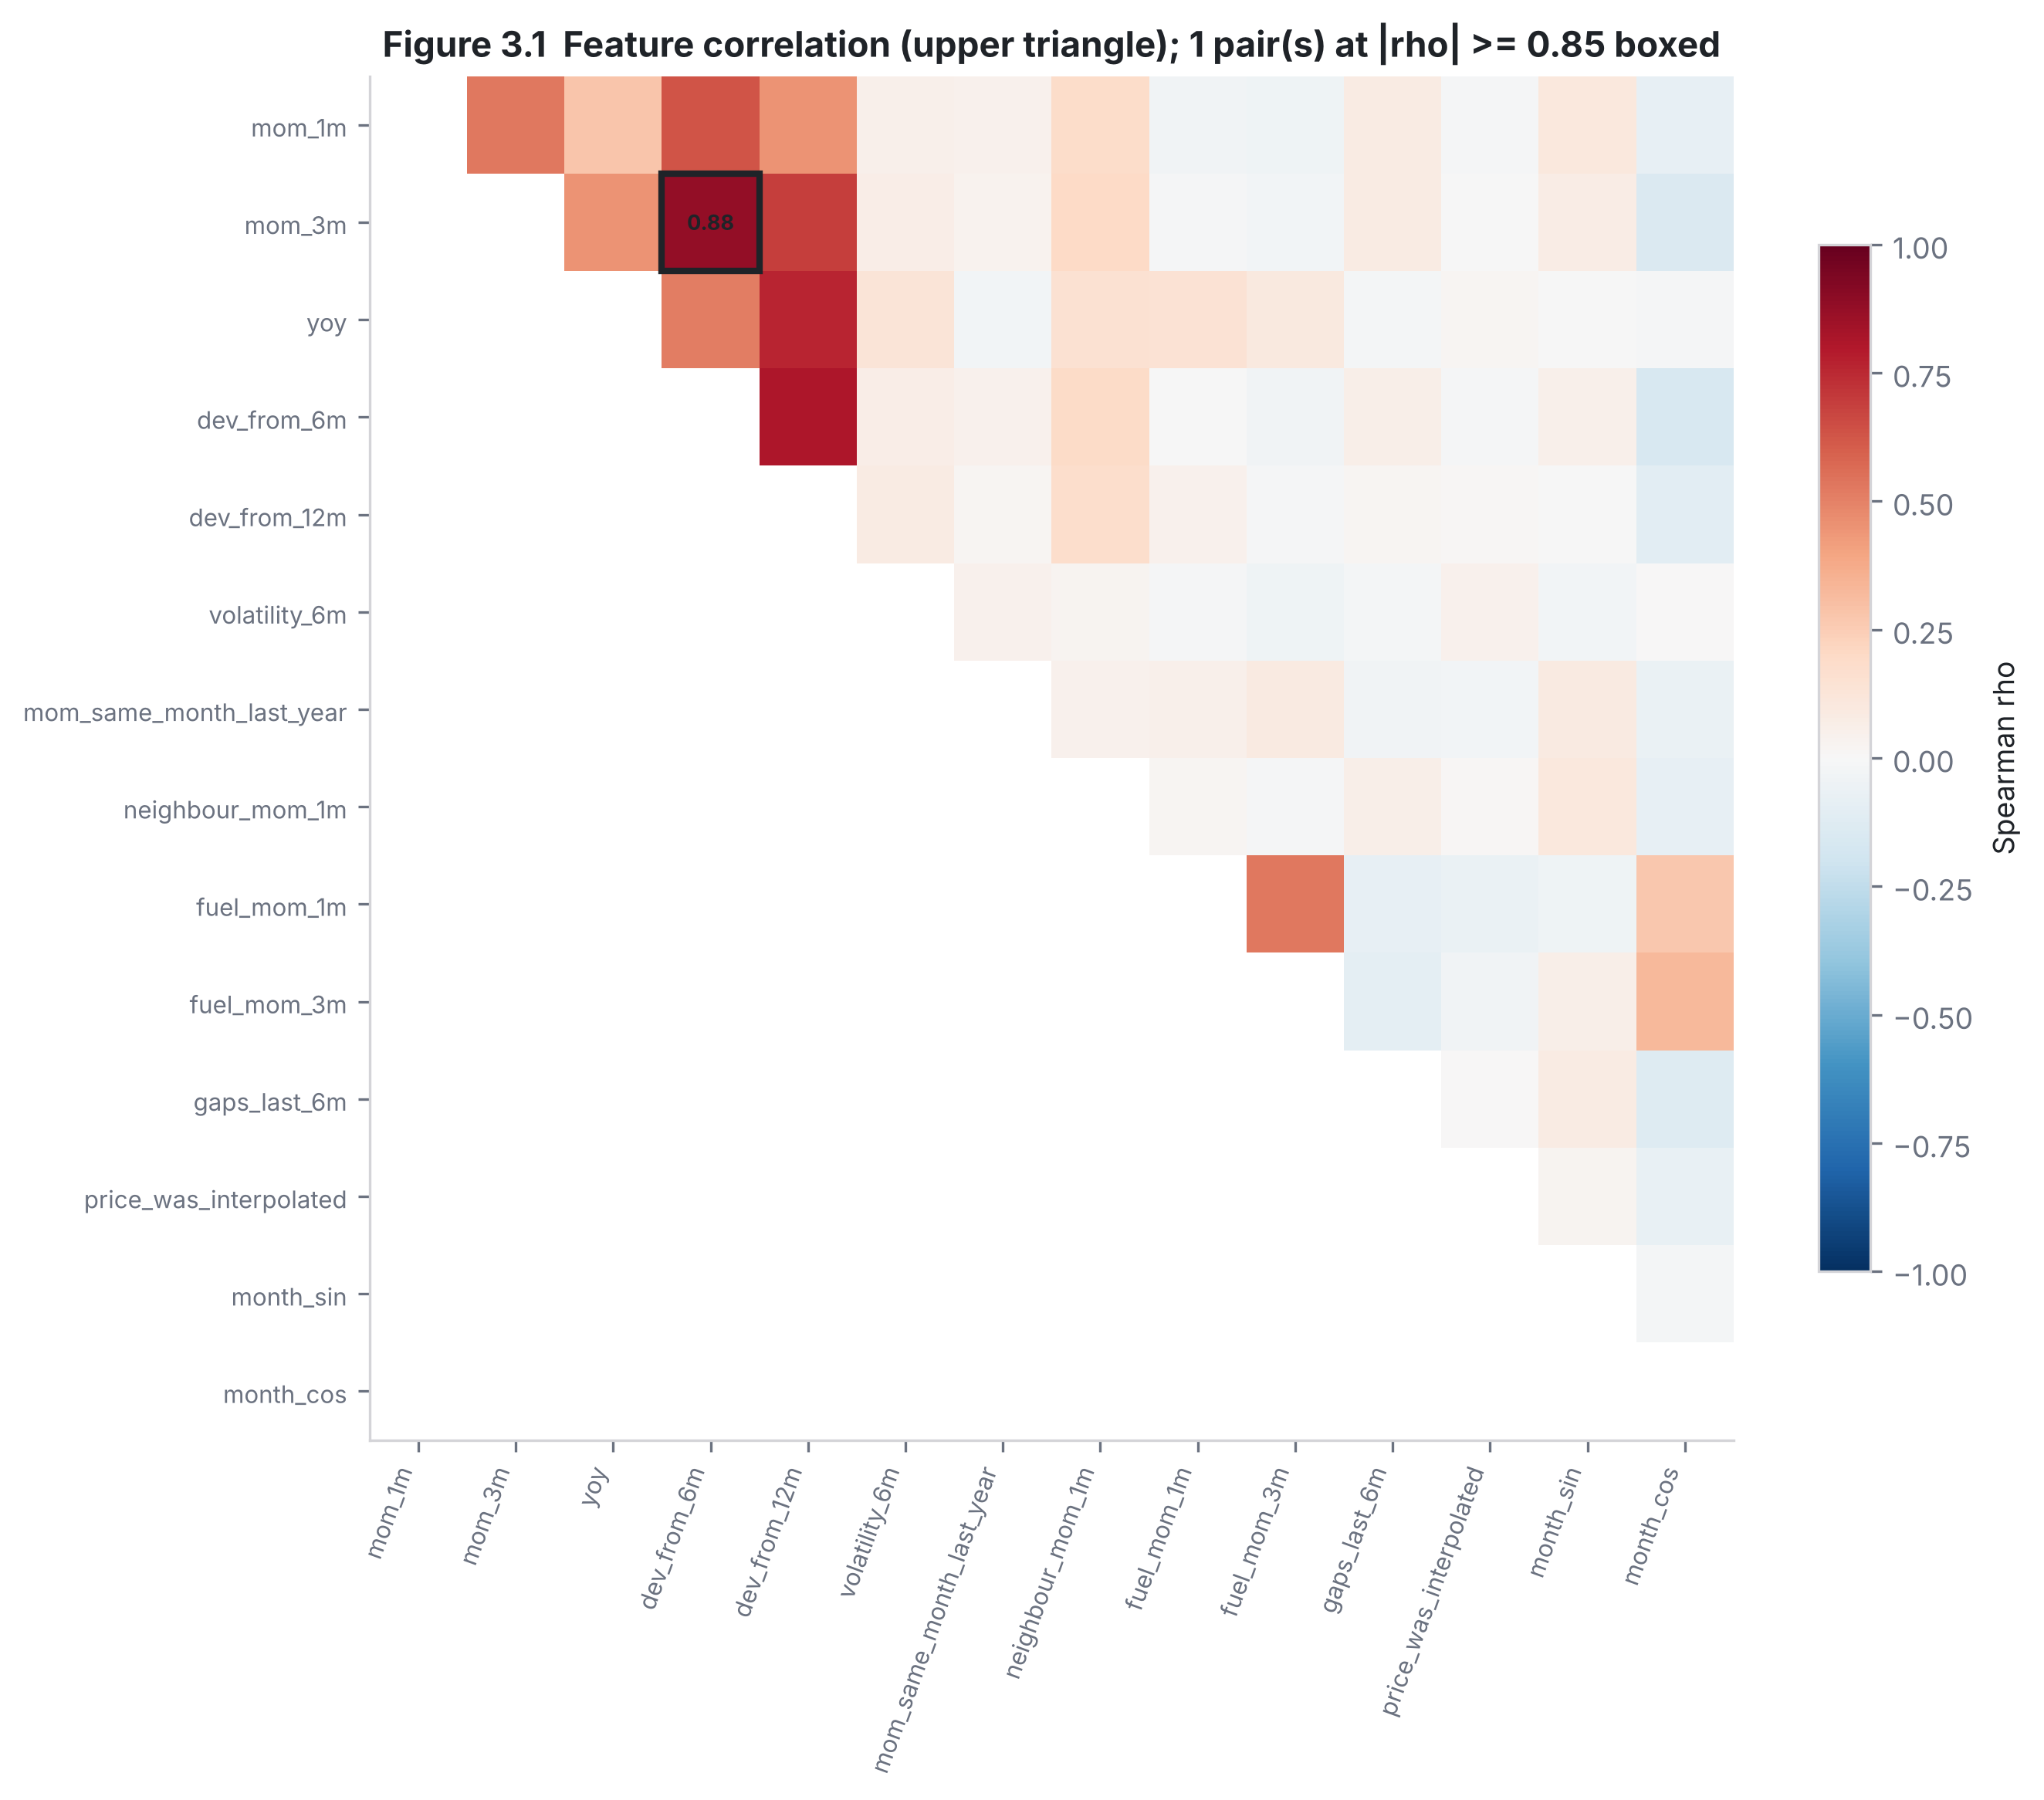

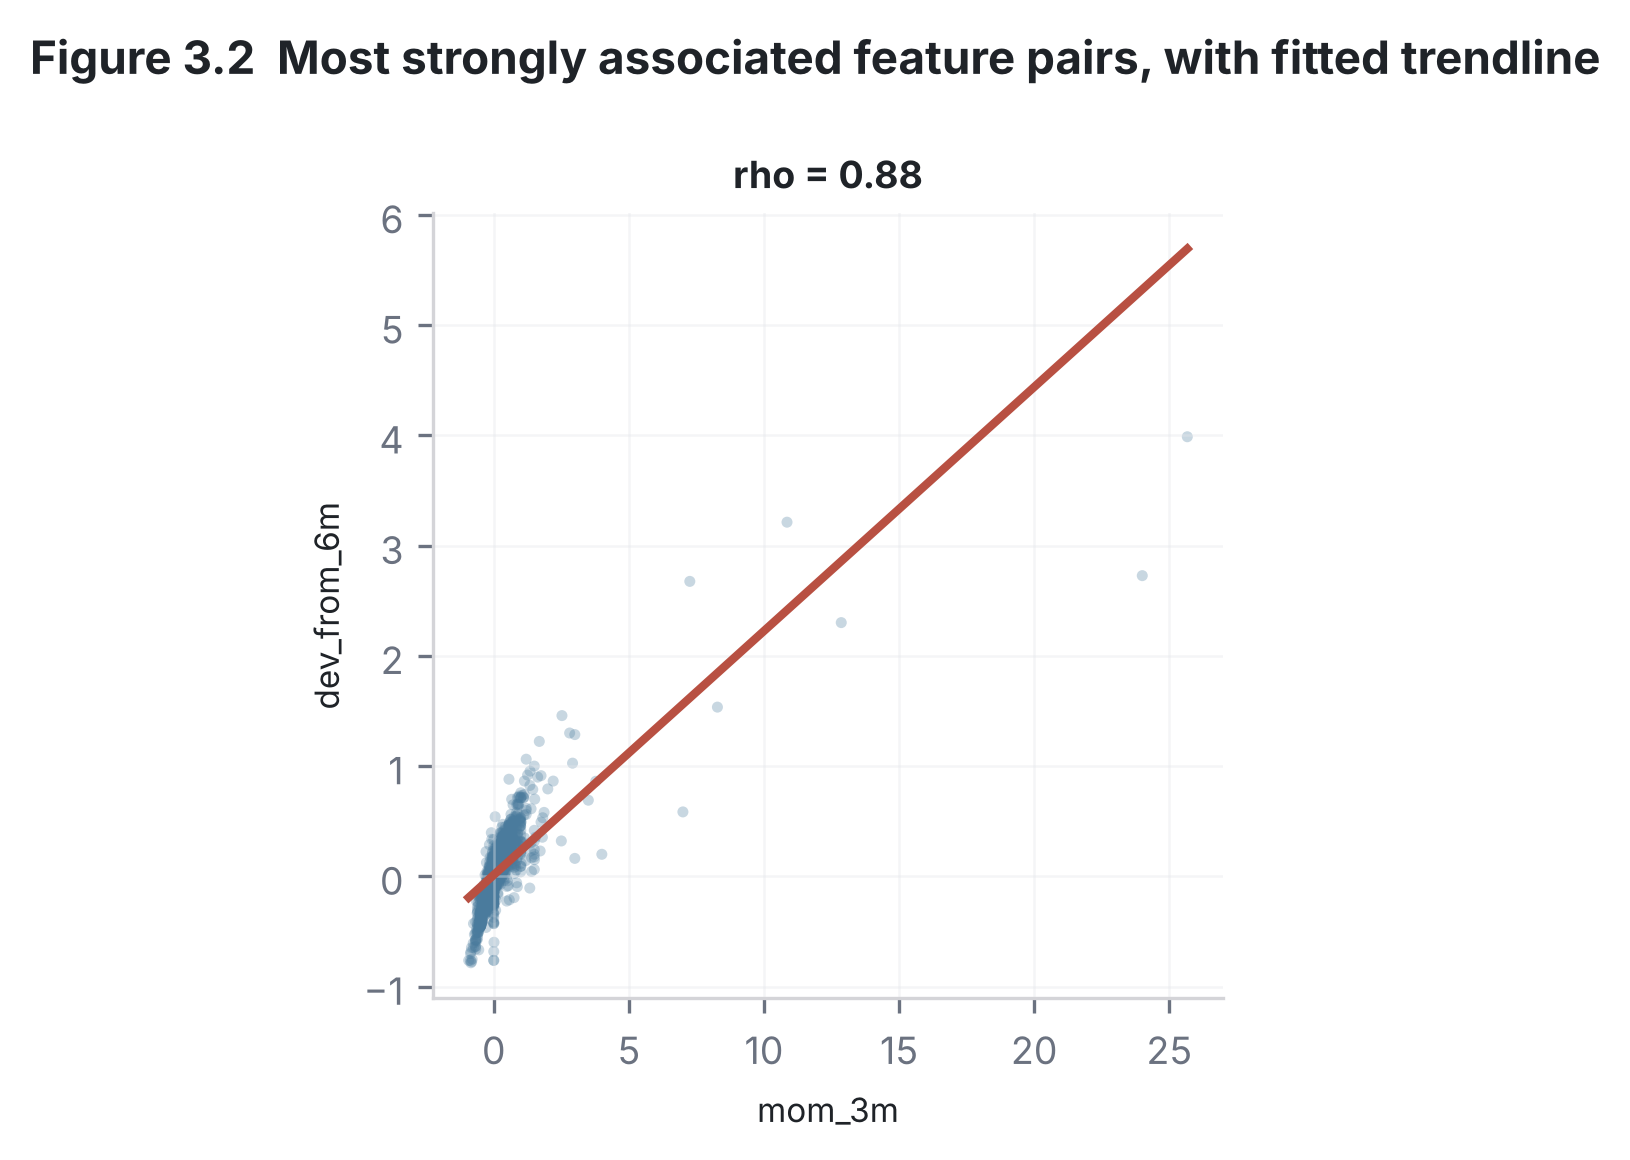

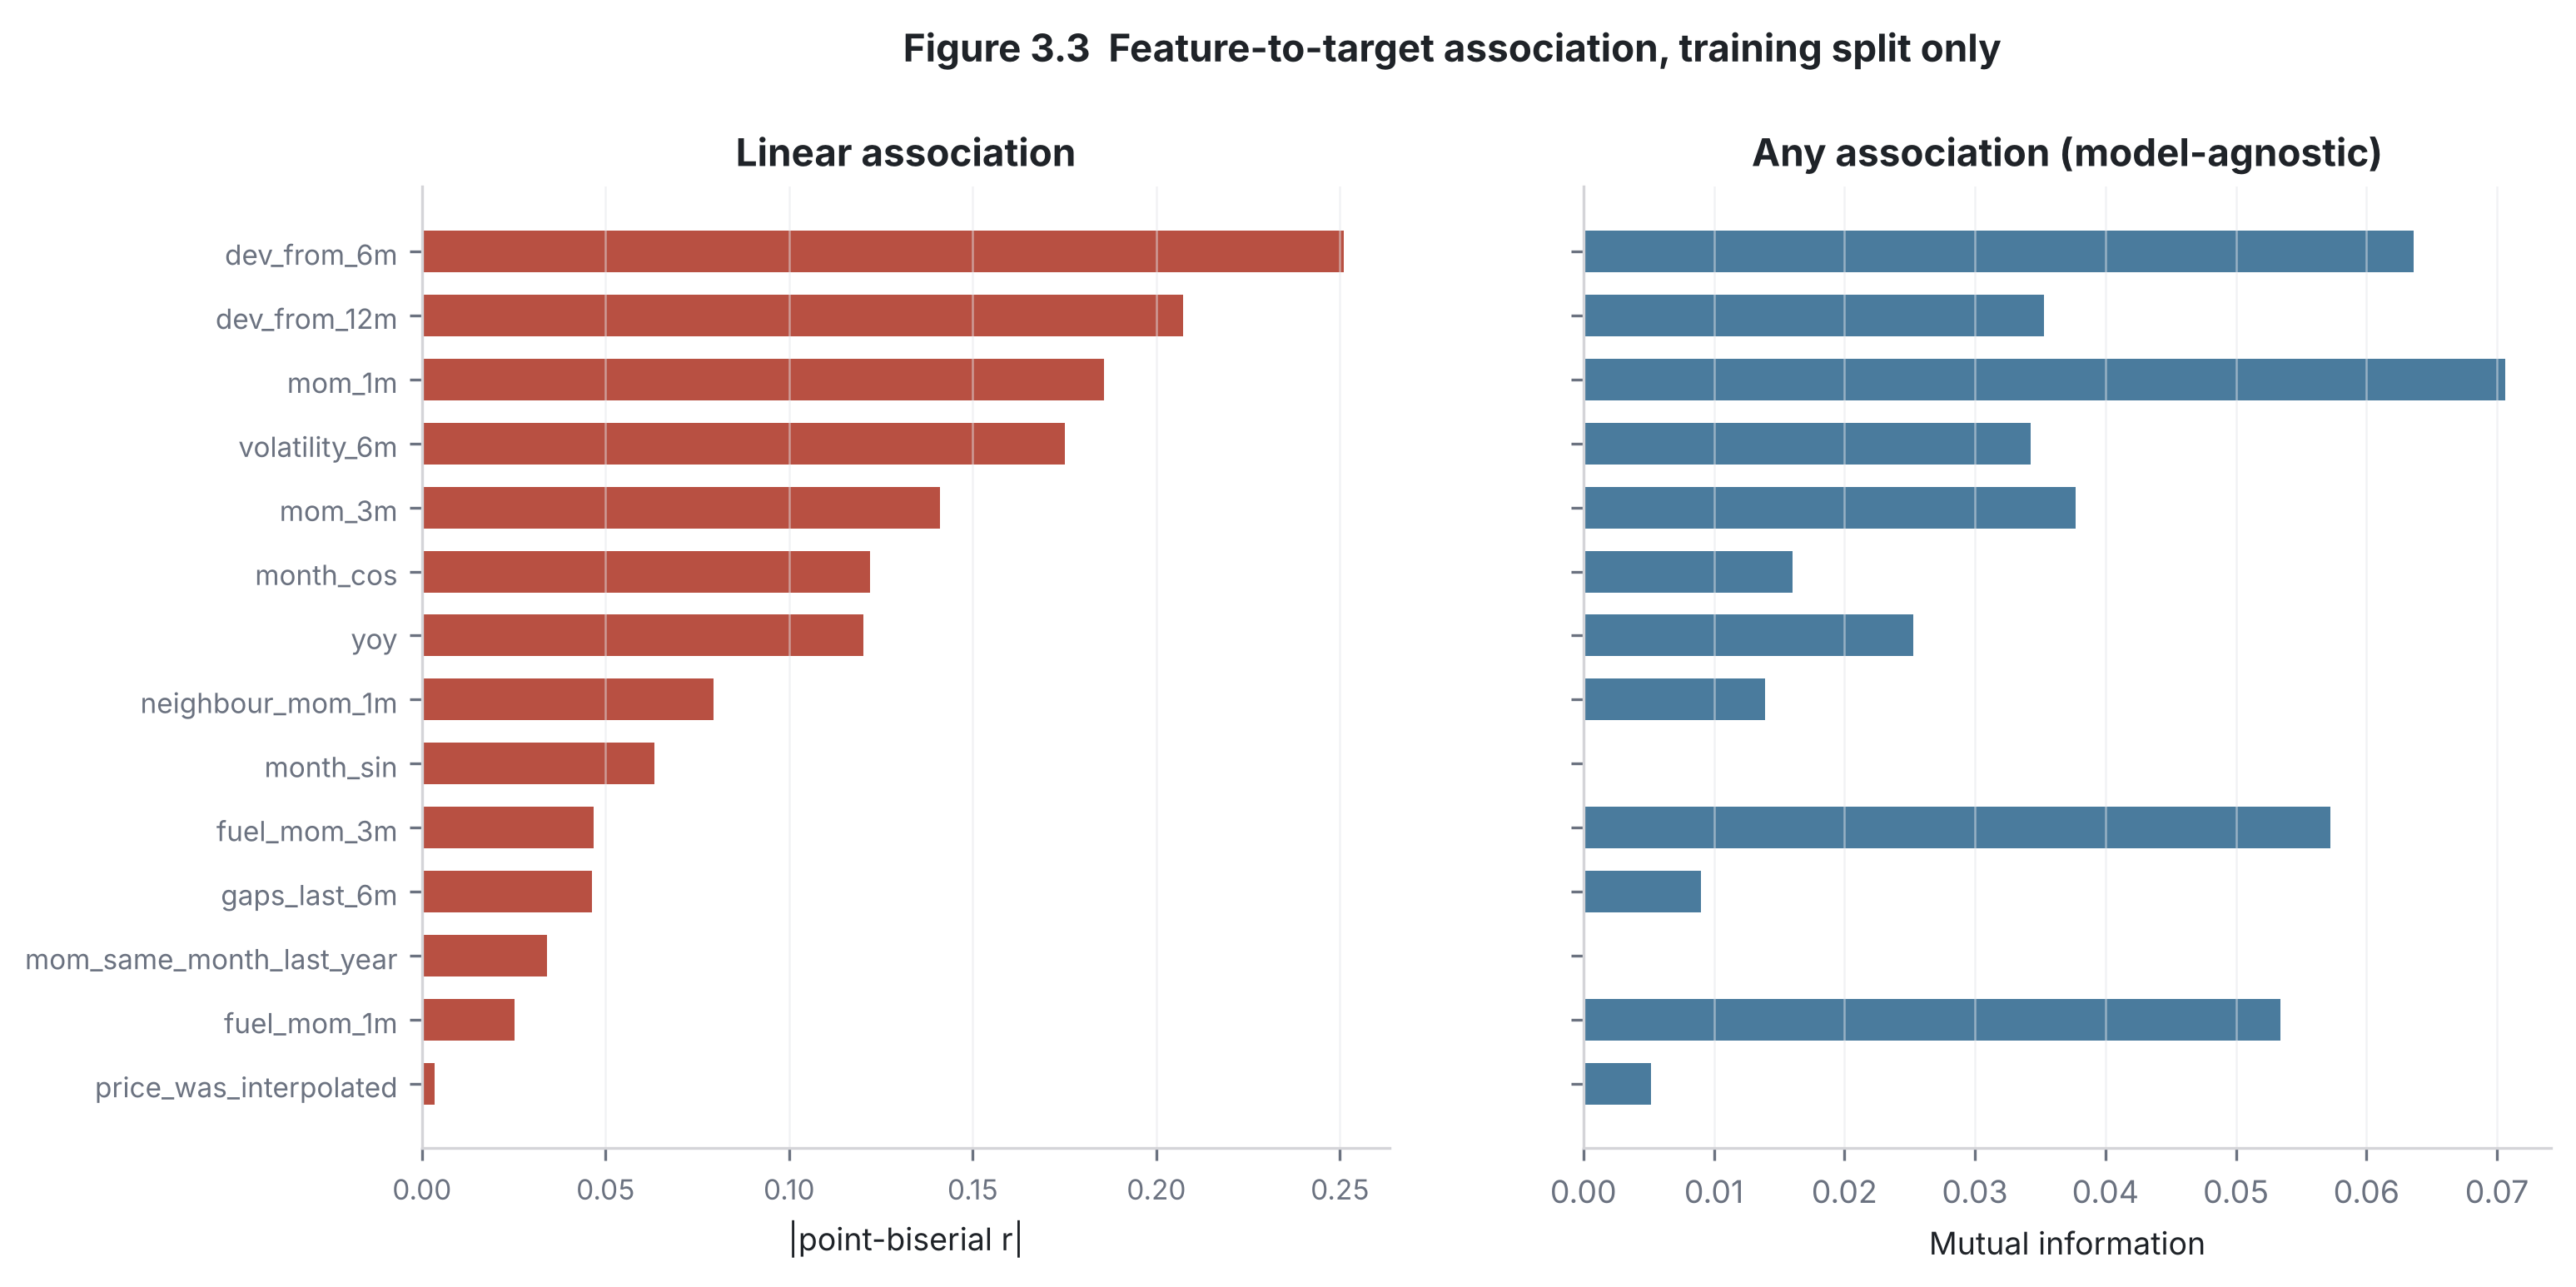

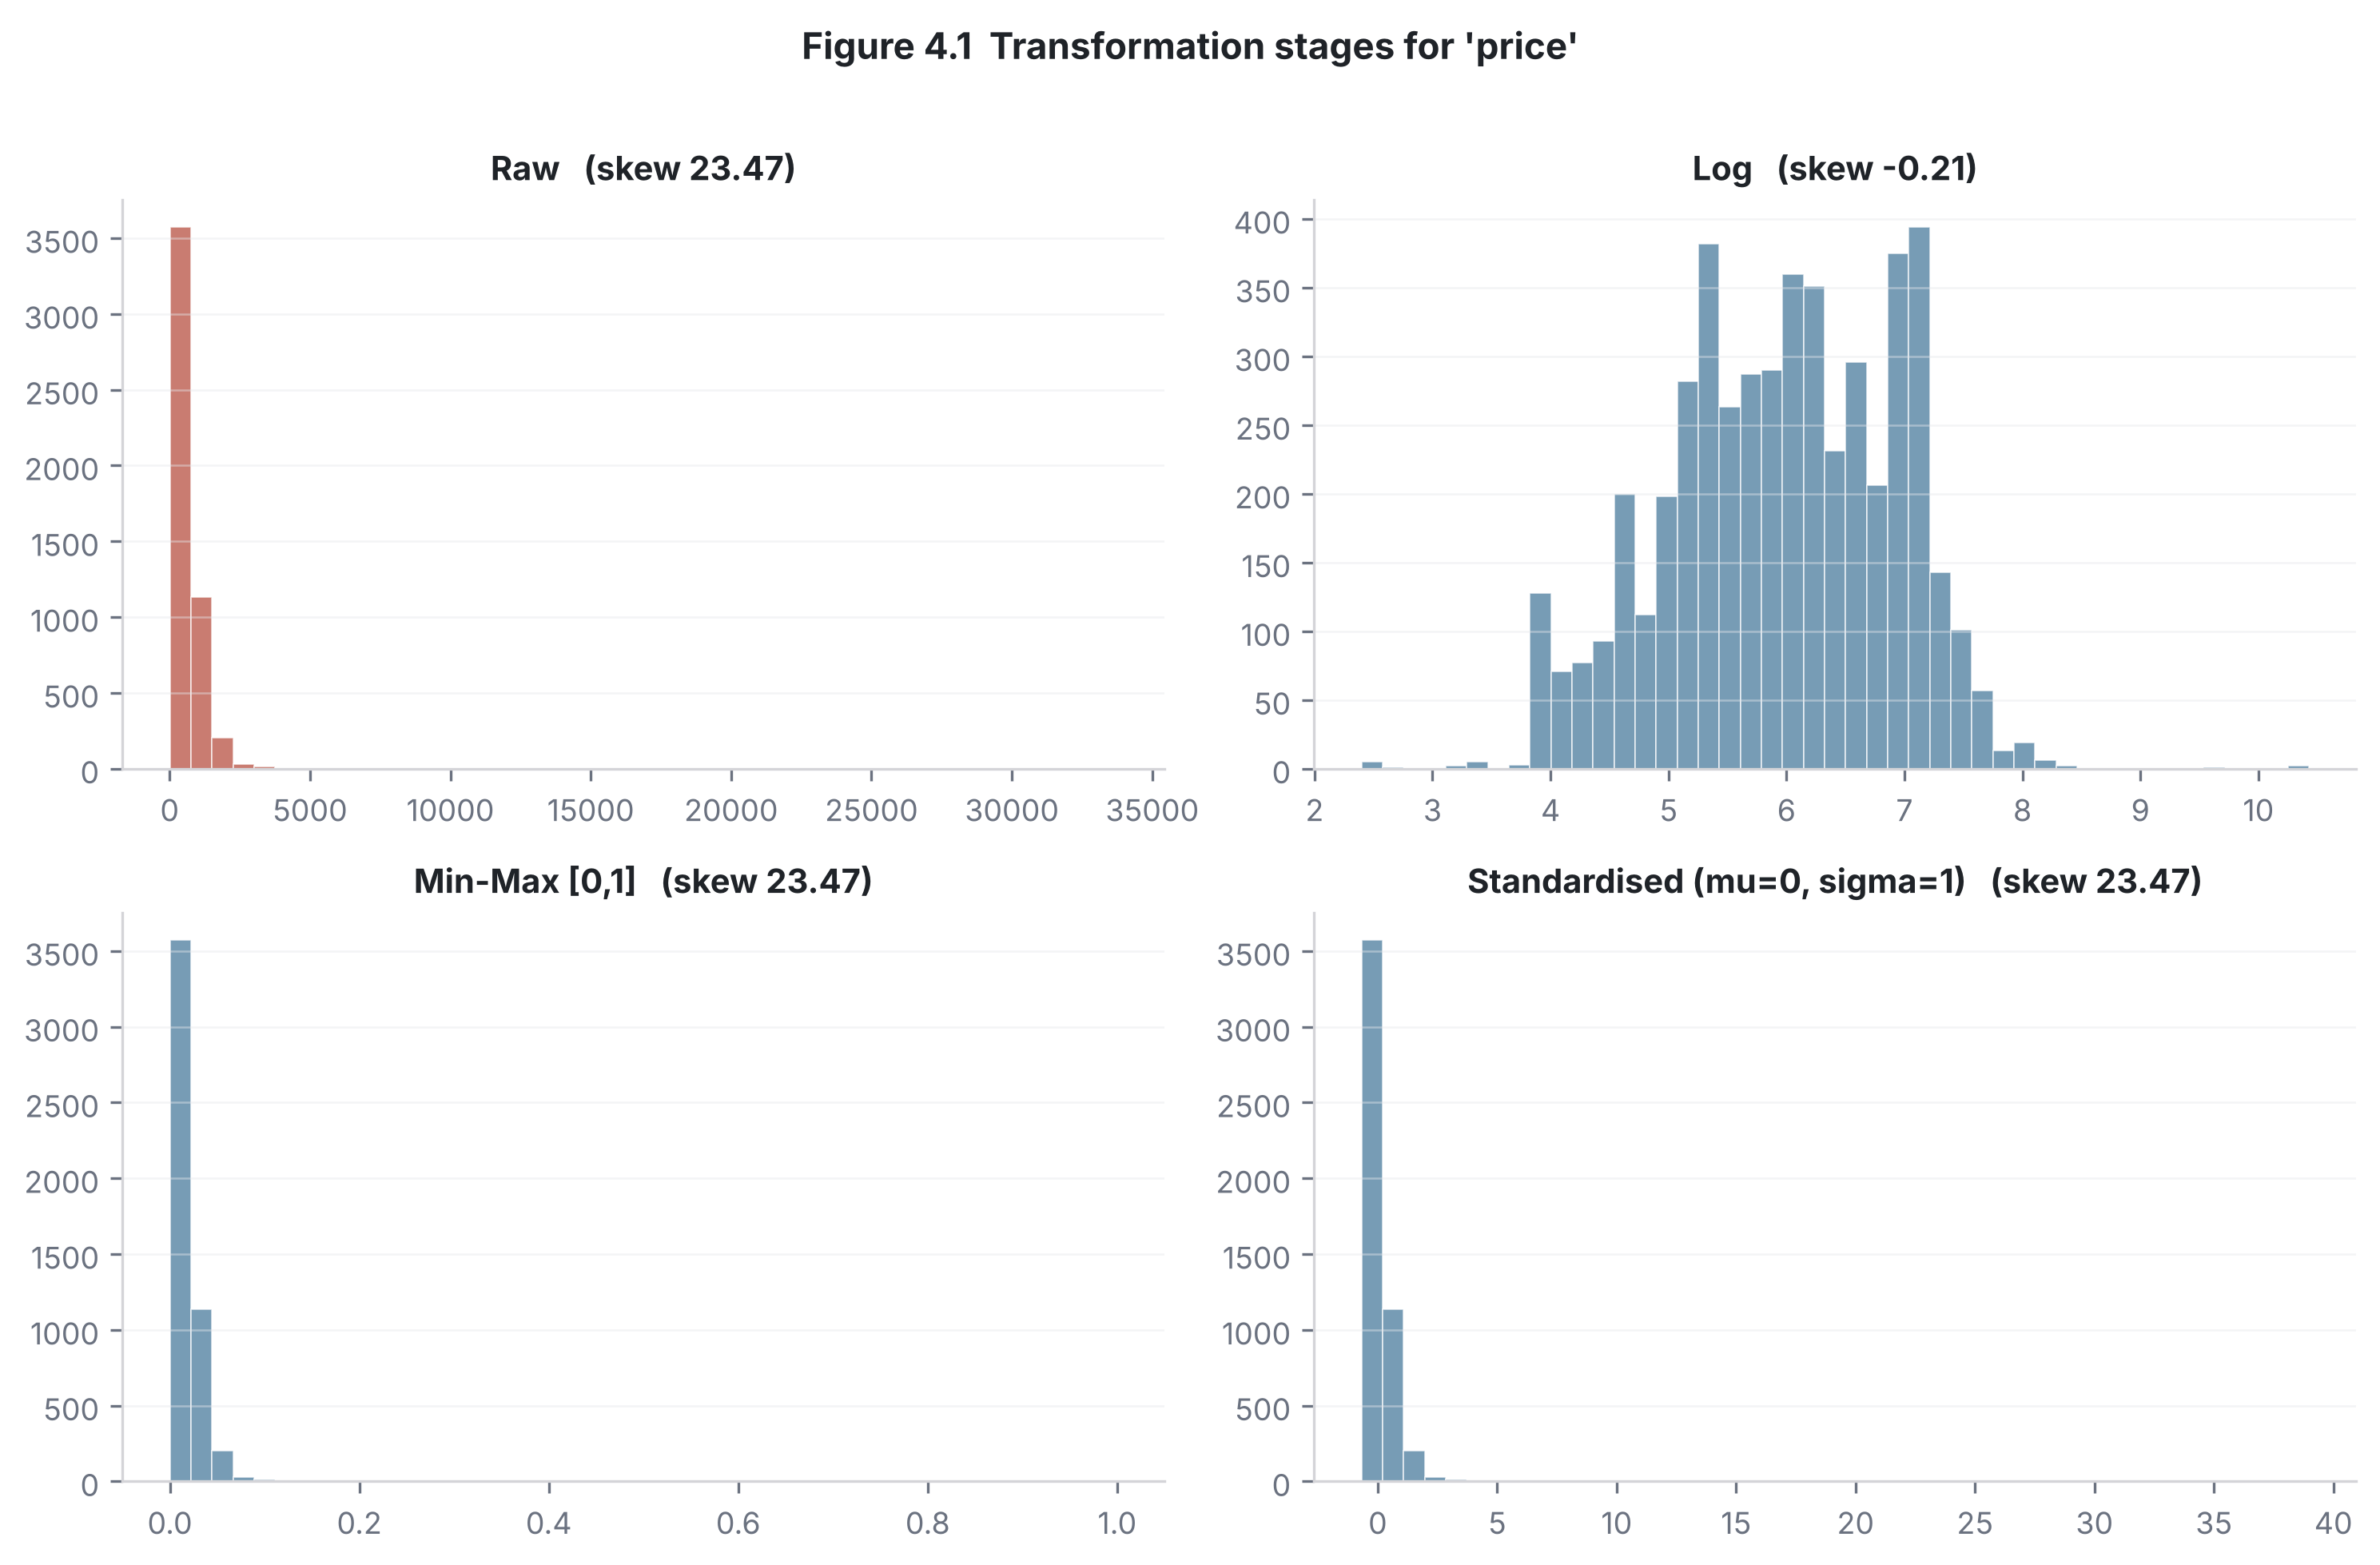

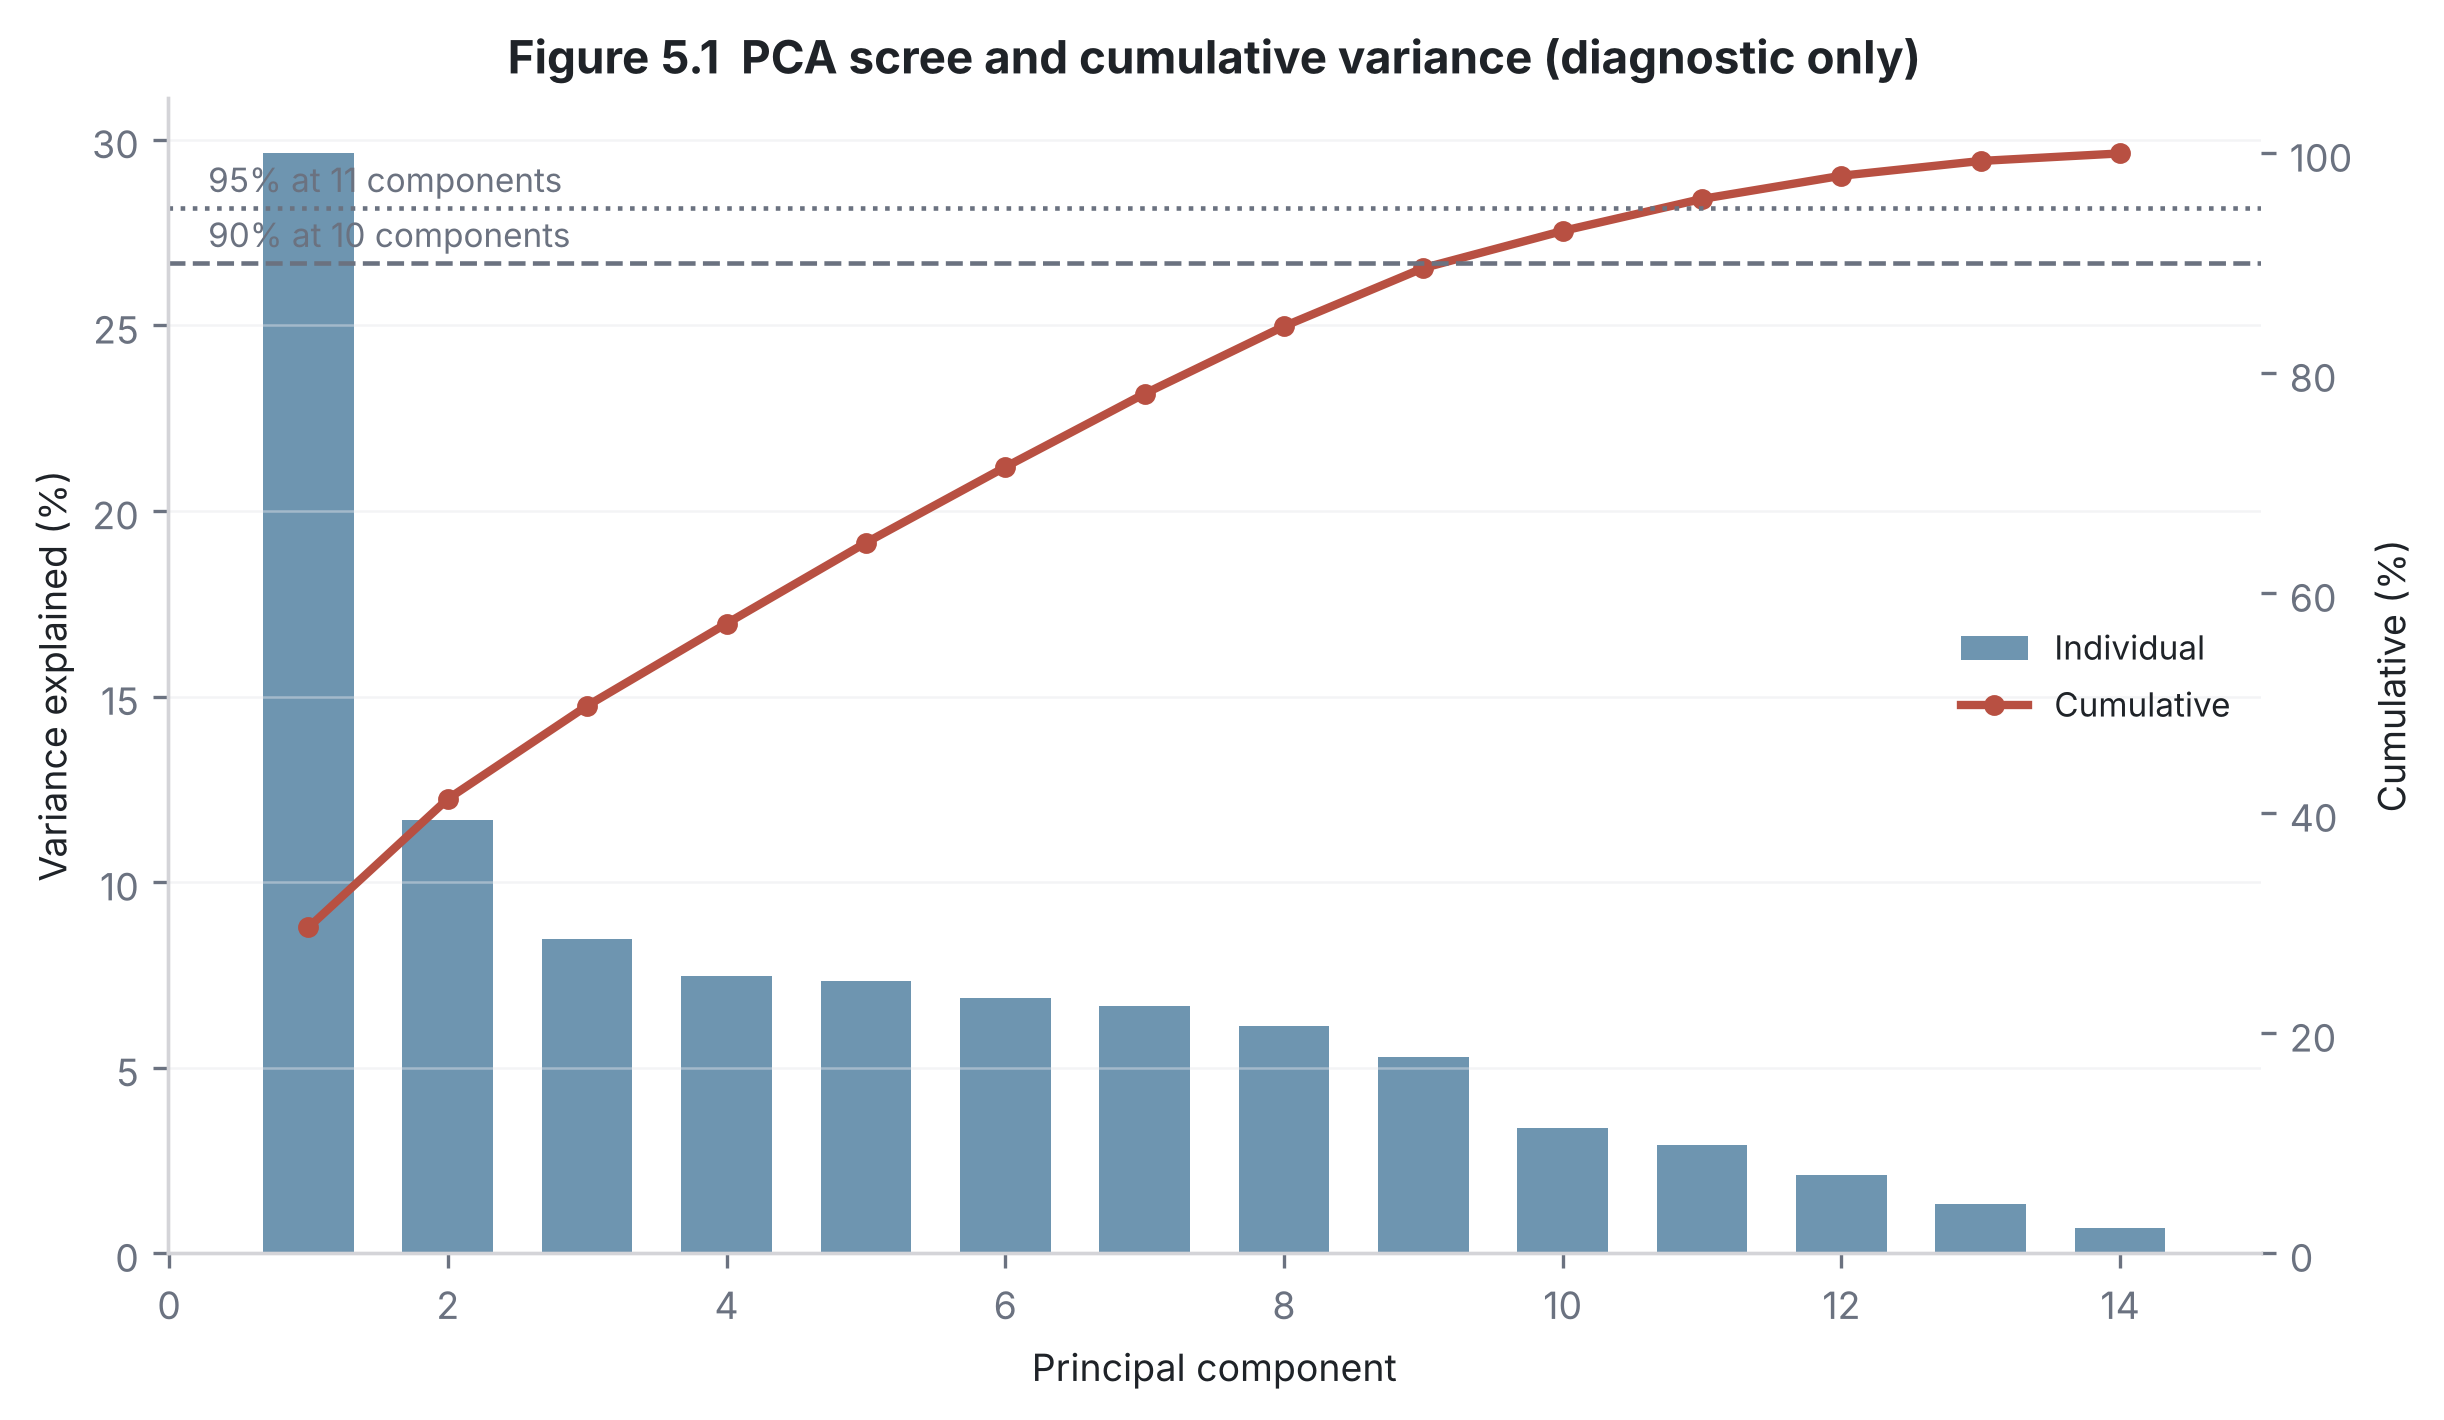

In [7]:
from IPython.display import Image, display
for p in paths:
    display(Image(filename=p, width=760))

### 2.1 Reading the figures

**Figure 2.1** shows ratio features before and after capping, not prices.
Price levels are never capped: an extreme upward movement *is* the target
event, so winsorising prices would delete positive cases from the training
data. The IQR screen is used diagnostically, to separate implausible values
from genuine extremes.

**Figure 3.1** flags collinearity that is expected by construction, since
momentum over one and three months share a term.

**Figure 5.1** is diagnostic only. PCA is not adopted as a transformation: the
components are dominated by the collinear lag features and would destroy the
interpretability the logistic model exists to provide.

## 3. Model pipelines

Both pipelines share one feature stage. Scaling and collinearity reduction are
applied to the logistic model only, because trees split on rank order and are
invariant to monotonic rescaling.

Every fitted transformation, imputation values, capping bounds and scaler
statistics, is learned inside the pipeline and therefore on `X_train` alone.

In [8]:
y_train = train[TARGET].astype(int)
y_val   = val[TARGET].astype(int)
y_test  = test[TARGET].astype(int)

logistic = build_logistic_pipeline().fit(train, y_train)
trees    = set_positive_class_weight(build_tree_pipeline(), y_train).fit(train, y_train)

print(logistic.named_steps["prep"])

ColumnTransformer(transformers=[('ratios',
                                 Pipeline(steps=[('cap',
                                                  RatioCapper(columns=['mom_1m',
                                                                       'mom_3m',
                                                                       'yoy',
                                                                       'dev_from_6m',
                                                                       'dev_from_12m',
                                                                       'volatility_6m',
                                                                       'mom_same_month_last_year',
                                                                       'neighbour_mom_1m',
                                                                       'fuel_mom_1m',
                                                                       'fuel_mom_3m'])),
                                  

### 3.1 Threshold selection on validation, never on test

The decision threshold is chosen as the one that meets the recall target of
0.80 on the **validation** split at the highest available precision. The test
split is scored once, at that threshold.

In [9]:
from sklearn.metrics import (recall_score, precision_score,
                             average_precision_score, roc_auc_score, brier_score_loss)

def choose_threshold(model, X, y, recall_target=0.80):
    p = model.predict_proba(X)[:, 1]
    best = (0.5, 0.0, 0.0)
    for t in np.arange(0.05, 0.95, 0.01):
        pred = (p > t).astype(int)
        r = recall_score(y, pred)
        pr = precision_score(y, pred, zero_division=0)
        if r >= recall_target and pr > best[2]:
            best = (t, r, pr)
    return best

def evaluate(name, model, thr, k=50):
    p = model.predict_proba(test)[:, 1]
    pred = (p > thr).astype(int)
    topk = np.argsort(-p)[:k]
    return {
        "model": name,
        "threshold": round(thr, 2),
        "recall": round(recall_score(y_test, pred), 3),
        "precision": round(precision_score(y_test, pred, zero_division=0), 3),
        "PR-AUC": round(average_precision_score(y_test, p), 3),
        "ROC-AUC": round(roc_auc_score(y_test, p), 3),
        f"precision@{k}": round(float(y_test.values[topk].mean()), 3),
        "Brier": round(brier_score_loss(y_test, p), 3),
    }

rows = []
for name, model in [("Logistic regression", logistic), ("Gradient boosted trees", trees)]:
    thr, vr, vp = choose_threshold(model, val, y_val)
    print(f"{name}: threshold {thr:.2f} (validation recall {vr:.2f}, precision {vp:.2f})")
    rows.append(evaluate(name, model, thr))

base_pred = seasonal_persistence_baseline(train, test)
rows.append({
    "model": "Seasonal persistence baseline",
    "threshold": np.nan,
    "recall": round(recall_score(y_test, base_pred), 3),
    "precision": round(precision_score(y_test, base_pred, zero_division=0), 3),
    "PR-AUC": np.nan, "ROC-AUC": np.nan, "precision@50": np.nan, "Brier": np.nan,
})

results = pd.DataFrame(rows).set_index("model")
print("\nTest base rate: {:.3f}".format(y_test.mean()))
results

Logistic regression: threshold 0.37 (validation recall 0.80, precision 0.41)


Gradient boosted trees: threshold 0.39 (validation recall 0.80, precision 0.50)

Test base rate: 0.127


,threshold,recall,precision,PR-AUC,ROC-AUC,precision@50,Brier
model,,,,,,,
Logistic regression,0.37,0.835,0.194,0.353,0.737,0.48,0.189
Gradient boosted trees,0.39,0.504,0.195,0.301,0.635,0.50,0.177
Seasonal persistence baseline,NaN,0.043,0.714,NaN,NaN,NaN,NaN


### 3.2 What the numbers say

The recall target of 0.80 is met on test by the logistic model. The precision
target of 0.60 is **not** met at the operating threshold, which is an honest
finding rather than a tuning failure: at an 12.7% test base rate, catching most
spikes necessarily means accepting many false alarms.

Precision among the top 50 ranked warnings is the more operationally honest
number, since an agency acts on a ranked list under a fixed budget rather than
on every alert above a threshold. It sits well above the base rate, which is
the lift the system actually delivers.

The seasonal persistence baseline is precise but almost never fires, so it
catches very few spikes. Beating it on recall is therefore the meaningful
comparison, and both models do.

## 4. Leakage verification

In [10]:
# Negative control: inject a feature built from month t+1 and confirm the
# harness detects it. A pipeline that cannot detect injected leakage cannot
# be trusted to rule it out.
leaky_train = train.copy()
leaky_test  = test.copy()
leaky_train["LEAK"] = leaky_train["price_next"] / leaky_train["trail_mean"]
leaky_test["LEAK"]  = leaky_test["price_next"] / leaky_test["trail_mean"]

import src.pipeline_builder as pb
orig = pb.RATIO_FEATURES.copy()
pb.RATIO_FEATURES = orig + ["LEAK"]
leak_model = build_logistic_pipeline().fit(leaky_train, y_train)
leak_auc = roc_auc_score(y_test, leak_model.predict_proba(leaky_test)[:, 1])
pb.RATIO_FEATURES = orig   # restore

clean_auc = roc_auc_score(y_test, logistic.predict_proba(test)[:, 1])
print(f"ROC-AUC with injected future feature: {leak_auc:.3f}")
print(f"ROC-AUC of the real pipeline:         {clean_auc:.3f}")
print("\nDetector works" if leak_auc > clean_auc + 0.15 else "\nCheck the control")

ROC-AUC with injected future feature: 1.000
ROC-AUC of the real pipeline:         0.737

Detector works


**DEVIATION 3 (a correction to the Phase 1 plan).** Phase 1 committed to
rebuilding lag features inside every cross-validation fold. On implementation
this proved unnecessary, and the reasoning in the Phase 1 report was
over-cautious. Every window here looks strictly backwards from month t and the
label is built from month t+1, so a training row at time t touches only months
at or before t, all of which precede the split boundary. Nothing from the test
period can reach a training feature.

The requirement does bind for anything that **learns a parameter**: capping
bounds, imputation values, scaler statistics, target encodings and PCA. All of
those sit inside the `Pipeline` and are fitted on the training split only. The
distinction matters, and conflating the two is what produces either leakage or
needless complexity.

## 5. Pipeline output verification

In [11]:
X_train_t = logistic.named_steps["prep"].transform(train)
X_test_t  = logistic.named_steps["prep"].transform(test)
names = logistic.named_steps["prep"].get_feature_names_out()

print("Raw file:          {} x {}".format(*raw.shape))
print("Panel:             {} x {}".format(*panel.shape))
print("Labelled panel:    {} x {}".format(int(panel[TARGET].notna().sum()), panel.shape[1]))
print()
print("Train design matrix:", X_train_t.shape)
print("Test design matrix: ", X_test_t.shape)
print("Feature count after encoding:", len(names))
print("No NaNs after pipeline:", not np.isnan(X_train_t).any())
print()
print("Final features:")
for n in names:
    print("  -", n)

Raw file:          88545 x 16
Panel:             9000 x 32
Labelled panel:    6940 x 32

Train design matrix: (4956, 17)
Test design matrix:  (909, 17)
Feature count after encoding: 17
No NaNs after pipeline: True

Final features:
  - mom_1m
  - mom_3m
  - yoy
  - dev_from_6m
  - dev_from_12m
  - volatility_6m
  - mom_same_month_last_year
  - neighbour_mom_1m
  - fuel_mom_1m
  - fuel_mom_3m
  - gaps_last_6m
  - price_was_interpolated
  - month_sin
  - month_cos
  - state_Borno
  - state_Yobe
  - food_type_storable


In [12]:
# Persist the processed matrix for reuse.
pathlib.Path("data/processed").mkdir(parents=True, exist_ok=True)
panel.to_csv("data/processed/panel_labelled.csv", index=False)
results.to_csv("data/processed/phase2_results.csv")
print("Saved data/processed/panel_labelled.csv and phase2_results.csv")

Saved data/processed/panel_labelled.csv and phase2_results.csv
